# Activity7.03: Comparing IQ scores using a violin plot

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 02

Data: `iq_scores.csv`. 

## Activity7.03 — 01. Read IQ data and convert each group to a list

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
mydata = pd.read_csv(DATA_DIR / 'iq_scores.csv')
group_a = mydata[mydata.columns[0]].tolist()
group_b = mydata[mydata.columns[1]].tolist()
group_c = mydata[mydata.columns[2]].tolist()
group_d = mydata[mydata.columns[3]].tolist()
print('Input shape:', mydata.shape)
print('Group list lengths:', [len(g) for g in [group_a, group_b, group_c, group_d]])
print('Group list types:', [type(g).__name__ for g in [group_a, group_b, group_c, group_d]])
display(mydata.head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Input shape: (100, 4)
Group list lengths: [100, 100, 100, 100]
Group list types: ['list', 'list', 'list', 'list']


,group_a,group_b,group_c,group_d
0,118,126,108,93
1,103,89,89,99
2,125,90,114,91
3,107,101,116,110
4,111,102,126,80


## Activity7.03 — 02. Create the required long-form DataFrame

In [2]:
data = pd.DataFrame({
    'Groups': ['Group A'] * len(group_a) + ['Group B'] * len(group_b)
              + ['Group C'] * len(group_c) + ['Group D'] * len(group_d),
    'IQ score': group_a + group_b + group_c + group_d
})
print(data.columns)
print('Long-form shape:', data.shape)
display(data.groupby('Groups')['IQ score'].agg(['count', 'median', 'min', 'max']))

Index(['Groups', 'IQ score'], dtype='str')
Long-form shape: (400, 2)


,count,median,min,max
Groups,,,,
Group A,100,107.0,70,143
Group B,100,100.5,66,141
Group C,100,105.0,69,137
Group D,100,98.0,54,131


## Activity7.03 — 03. Draw the violin plot with the required styling

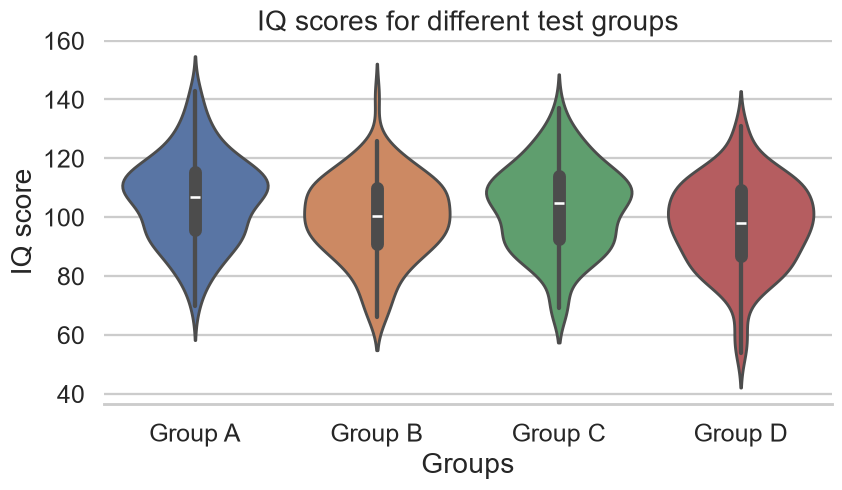

In [3]:
sns.set_theme(style='whitegrid', context='talk')
plt.figure(figsize=(8, 4.8), dpi=110)
sns.violinplot(data=data, x='Groups', y='IQ score', hue='Groups',
               palette='deep', legend=False, inner='box')
sns.despine(left=True, right=True, top=True)
plt.title('IQ scores for different test groups')
plt.tight_layout()
plt.show()

The four distributions overlap. Group A has a higher sample median than Group D. The violin outline is a kernel density estimate and may extend beyond observed extremes under the default smoothing settings.